## Clustering: KMeans++

- Se elige *k*, se valida la inicialización, la estabilidad y el espacio

- Se perfilan las tipologías de entidades y proveedores

- Spark MLlib (`KMeans` `ClusteringEvaluator`);

### Constantes

- `RANGO_K`: candidatos de *k*

- `SEMILLAS`: semillas para medir la estabilidad

- `RANGO_ESPACIO`: varianzas del PCA que se comparan

- `RANGO_FRAC`: fracciones de los datos para medir el tiempo al crecer n

In [1]:
RANGO_K = list(range(2, 11))
SEMILLAS = [42, 7, 13, 21, 99]
RANGO_ESPACIO = [0.70, 0.85, 0.95, "completo"]
RANGO_FRAC = [0.25, 0.5, 1.0]

### Utilidades

In [2]:
NOTEBOOK = "b_kmeans"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


In [4]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.functions import array_to_vector, vector_to_array
from sklearn.cluster import KMeans as KMeansSK

config = leer_config()
evaluador = lambda col: ClusteringEvaluator(featuresCol=col, predictionCol="cluster", metricName="silhouette",
                                            distanceMeasure="squaredEuclidean")

def kmeans(d, k, col="x", seed=SEED, init="k-means||"):
    return KMeans(k=k, seed=seed, featuresCol=col, predictionCol="cluster", initMode=init, maxIter=50).fit(d)

### Carga

- `x`: los `n_comp` primeros componentes del PCA elegido en `a_preparacion`

- `z`: las features estandarizadas completas

In [5]:
prep = {}
for s, c in config.items():
    prep[s] = (leer(datos_dir, f"prep_{s}")
               .withColumn("x", array_to_vector(F.slice("pcs", 1, c["n_comp"])))
               .withColumn("zv", array_to_vector("z")).cache())
    print(f"{s}: {prep[s].count():,} actores | {c['n_comp']} componentes")

entidad: 2,696 actores | 6 componentes


proveedor: 13,317 actores | 6 componentes


---
### **1. Elección de *k***

- **Codo:** WSSSE baja siempre con k; se busca dónde deja de bajar rápido

- **Silueta:** cohesión vs separación, de -1 a 1; se busca el máximo

In [6]:
curvas, modelos = [], {}
for s, d in prep.items():
    for k in RANGO_K:
        t0 = time.time(); m = kmeans(d, k)
        curvas.append({"sujeto": s, "k": k, "wssse": round(m.summary.trainingCost, 1),
                       "silueta": round(evaluador("x").evaluate(m.transform(d)), 4), "seg": round(time.time() - t0, 1)})
        modelos[(s, k)] = m
curvas = pd.DataFrame(curvas)
curvas.pivot(index="k", columns="sujeto", values=["wssse", "silueta"])

wssse           silueta          
sujeto  entidad proveedor entidad proveedor
k                                          
2       19008.2  103595.1  0.3100    0.3975
3       16285.9   88512.1  0.3057    0.4348
4       13789.9   68623.5  0.3342    0.5155
5       12941.0   60286.5  0.3052    0.3464
6       12165.4   51014.5  0.2815    0.3917
7       11468.4   46500.5  0.2457    0.3597
8       10839.1   43002.4  0.2655    0.3683
9       10214.8   40674.7  0.2674    0.3452
10       9641.9   38054.5  0.2785    0.3545

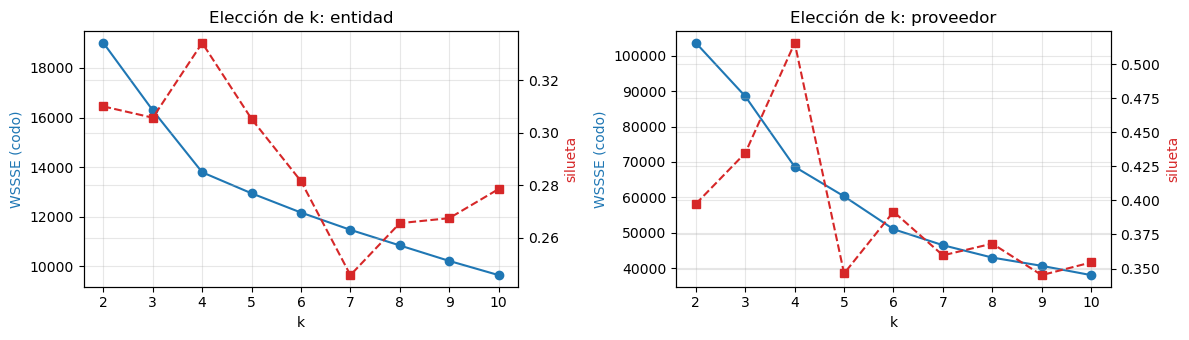

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i, s in enumerate(prep):
    c = curvas[curvas.sujeto == s]
    ax[i].plot(c.k, c.wssse, "o-", color="tab:blue"); ax[i].set_ylabel("WSSSE (codo)", color="tab:blue")
    a2 = ax[i].twinx(); a2.plot(c.k, c.silueta, "s--", color="tab:red"); a2.set_ylabel("silueta", color="tab:red")
    ax[i].set_title(f"Elección de k: {s}"); ax[i].set_xlabel("k")
mostrar_fig("eleccion_k")

- **Silueta máxima en k = 4** para ambos (entidades 0.334, proveedores 0.516)

- **Codo en k = 4:** el WSSSE de proveedores baja 19,889 de 3 a 4

- Se fija `K = 4` para entidades y proveedores: coinciden el codo y la silueta

In [8]:
for s in config:
    config[s]["k"] = K[s]
guardar_config(config)

---
### 2. Inicialización: KMeans++ vs aleatoria

`k-means||` es la versión distribuida de **KMeans++**

In [9]:
inicios = []
for s, d in prep.items():
    for init in ["k-means||", "random"]:
        t0 = time.time(); m = kmeans(d, K[s], init=init)
        inicios.append({"sujeto": s, "init": init, "wssse": round(m.summary.trainingCost, 1), "iteraciones": m.summary.numIter,
                        "silueta": round(evaluador("x").evaluate(m.transform(d)), 4), "seg": round(time.time() - t0, 1)})
inicios = pd.DataFrame(inicios)
inicios

,sujeto,init,wssse,iteraciones,silueta,seg
0,entidad,k-means||,13789.9,15,0.3342,1.6
1,entidad,random,13789.9,14,0.3342,0.9
2,proveedor,k-means||,68623.5,18,0.5155,1.6
3,proveedor,random,68623.5,30,0.5155,1.5


- Con k = 4, KMeans++ (`k-means||`) y aleatoria llegan al mismo **WSSSE** y silueta

- KMeans++ converge en **18 iteraciones contra 30** en proveedores

- Se usa KMeans++: mismo resultado y en menos iteraciones

---
### **3. Estabilidad entre semillas**

Si la partición cambia mucho con la semilla, las tipologías no son confiables

In [10]:
etiquetas = {s: {sd: kmeans(d, K[s], seed=sd).transform(d).select(config[s]["key"], "cluster").toPandas()
                     .set_index(config[s]["key"]).cluster for sd in SEMILLAS} for s, d in prep.items()}
estabilidad = pd.DataFrame([{"sujeto": s, "semilla_a": a, "semilla_b": b, "ari": round(ari(e[a], e[b].loc[e[a].index]), 3)}
                            for s, e in etiquetas.items() for i, a in enumerate(SEMILLAS) for b in SEMILLAS[i + 1:]])
estabilidad.groupby("sujeto").ari.describe()[["min", "mean", "max"]].round(3)

,min,mean,max
sujeto,,,
entidad,0.994,0.996,1.0
proveedor,0.634,0.853,1.0


- **ARI**: compara dos particiones, 1 = idénticas, ≈ 0 = como al azar

- **Entidades:** ARI ≥ 0.994 entre las 5 semillas: la partición es prácticamente la misma

- **Proveedores:** ARI medio 0.853 (mínimo 0.634)

- Las tipologías grandes se mantienen; los bordes entre ellas varían

---
### **4. Espacio: PCA vs features completas**

Cada espacio se agrupa con el k elegido y la silueta se mide

In [11]:
espacio = []
for s, d in prep.items():
    for e in RANGO_ESPACIO:
        if e == "completo":
            dd, col, nc = d, "zv", len(config[s]["feats"])
        else:
            nc = int((np.array(config[s]["acumulada"]) < e).sum() + 1)
            dd, col = d.withColumn("xe", array_to_vector(F.slice("pcs", 1, nc))), "xe"
        p = kmeans(dd, K[s], col=col).transform(dd)
        espacio.append({"sujeto": s, "espacio": e, "dimensiones": nc, "silueta_en_z": round(evaluador("zv").evaluate(p), 4)})
espacio = pd.DataFrame(espacio)
espacio.pivot(index="espacio", columns="sujeto", values=["dimensiones", "silueta_en_z"])

dimensiones           silueta_en_z          
sujeto       entidad proveedor      entidad proveedor
espacio                                              
0.7              4.0       4.0       0.2918    0.4514
0.85             6.0       6.0       0.2917    0.4583
0.95             8.0       9.0       0.2924    0.4670
completo        10.0      12.0       0.2931    0.4682

- La silueta medida en las features completas casi no cambia con el espacio

- El PCA al 85% pierde a lo sumo 0.01 de silueta frente al espacio completo

---
### **5. Comparación: Spark MLlib vs sklearn**

- Mismo k, mismos datos y KMeans++ en ambos: deberían dar la misma partición (ARI ≈ 1)

- Se compara además el tiempo al crecer n

In [12]:
referencia = []
for s, d in prep.items():
    for frac in RANGO_FRAC:
        dd = d.sample(fraction=frac, seed=SEED) if frac < 1 else d
        loc = dd.select(config[s]["key"], vector_to_array("x").alias("x")).toPandas()
        X = np.vstack(loc.x.to_numpy())
        t0 = time.time(); p = kmeans(dd, K[s]).transform(dd).select(config[s]["key"], "cluster").toPandas(); t_sp = time.time() - t0
        t0 = time.time(); sk = KMeansSK(n_clusters=K[s], init="k-means++", n_init=1, random_state=SEED).fit(X); t_sk = time.time() - t0
        lab_sp = loc[[config[s]["key"]]].merge(p, on=config[s]["key"]).cluster.to_numpy()
        referencia.append({"sujeto": s, "fraccion": frac, "n": len(X), "ari_spark_sklearn": round(ari(lab_sp, sk.labels_), 3),
                           "seg_spark": round(t_sp, 2), "seg_sklearn": round(t_sk, 2)})
referencia = pd.DataFrame(referencia)
referencia

,sujeto,fraccion,n,ari_spark_sklearn,seg_spark,seg_sklearn
0,entidad,0.25,692,0.982,0.61,0.12
1,entidad,0.50,1376,0.957,0.73,0.04
2,entidad,1.00,2696,0.994,0.73,0.12
3,proveedor,0.25,3429,0.980,0.87,0.13
4,proveedor,0.50,6768,0.495,1.27,0.10
5,proveedor,1.00,13317,0.796,1.11,0.12


- **Spark vs sklearn:** ARI de 0.96-0.99 en entidades y proveedores con partición

- En proveedores completos el ARI baja a 0.80 (0.50 en la mitad)

- **Tiempo:** sklearn tarda ~0.1 s y Spark ~1 s. 

- Con este n, el costo fijo de Spark (planificar y distribuir) domina

---
### **6. Modelo final y perfiles**

`dist_centro`: distancia de cada actor a su centroide

In [13]:
perfiles, lejanos = {}, []
for s, d in prep.items():
    key, feats, m = config[s]["key"], config[s]["feats"], modelos[(s, K[s])]
    centros = np.array(m.clusterCenters())
    p = m.transform(d).select(key, "cluster", vector_to_array("x").alias("x")).toPandas()
    p["dist_centro"] = np.linalg.norm(np.vstack(p.x.to_numpy()) - centros[p.cluster], axis=1)
    p[[key, "cluster", "dist_centro"]].to_parquet(datos_dir / f"kmeans_{s}", index=False)

    loc = pd.read_parquet(datos_dir / f"prep_{s}").merge(p[[key, "cluster", "dist_centro"]], on=key)
    monto = "monto_adjudicado_total" if s == "entidad" else "monto_total"
    g = loc.groupby("cluster")
    pr = pd.DataFrame({"n": g.size(), "pct_actores": (100 * g.size() / len(loc)).round(1),
                       "pct_monto": (100 * g[monto].sum() / loc[monto].sum()).round(1),
                       "mediana_procesos": g.n_procesos.median(), "mediana_monto": g[monto].median().round(0)})
    perfiles[s] = pr.join(perfil_z(loc, feats, "cluster")[["rasgos"]])
    lejanos.append(loc.nlargest(10, "dist_centro")[[key, "nombre", "cluster", "dist_centro", "n_procesos", monto]]
                      .rename(columns={key: "clave", monto: "monto"}).assign(sujeto=s))
display(perfiles["entidad"]); display(perfiles["proveedor"])

,n,pct_actores,pct_monto,mediana_procesos,mediana_monto,rasgos
cluster,,,,,,
0,909,33.7,2.4,17.0,3812999.0,"log_monto_total ↓0.8σ, log_monto_mediano ↓0.7σ, log_n_procesos ↓0.7σ"
1,234,8.7,13.8,53.5,25543935.0,"pct_postor_unico ↑2.4σ, pct_directa ↑2.2σ, log_postores_promedio ↓0.8σ"
2,680,25.2,6.6,22.0,14437553.0,"pct_obras ↑1.3σ, log_monto_mediano ↑0.8σ, pct_bienes ↓0.7σ"
3,873,32.4,77.2,118.0,49981212.0,"log_n_procesos ↑1.0σ, log_monto_total ↑0.8σ, share_top_proveedores ↓0.7σ"


,n,pct_actores,pct_monto,mediana_procesos,mediana_monto,rasgos
cluster,,,,,,
0,2394,18.0,50.4,16.0,4548582.0,"log_n_entidades ↑1.6σ, meses_activos ↑1.5σ, log_n_regiones ↑1.4σ"
1,8252,62.0,14.5,4.0,735895.0,"pct_postor_unico ↓0.4σ, meses_activos ↓0.3σ, log_n_entidades ↓0.3σ"
2,1650,12.4,2.7,3.0,229986.0,"pct_postor_unico ↑2.2σ, tasa_exito ↑1.8σ, pct_directa ↑1.0σ"
3,1021,7.7,32.4,5.0,10417264.0,"pct_obras ↑2.7σ, log_monto_mediano ↑2.0σ, log_monto_total ↑1.3σ"


#### a. Entidades
- 0 = **compradoras pequeñas** (33.7% de entidades, 2.4% del monto; montos y procesos ↓)

- 1 = **compra sin competencia** (8.7%; postor único ↑2.4σ, directa ↑2.2σ)

- 2 = **compradoras de obras** (25.2%; obras ↑1.3σ)

- 3 = **grandes compradoras diversificadas** (32.4% de entidades y **77.2% del monto**; dependencia ↓)
  
#### b. Proveedores
- 0 = **grandes multicliente** (18.0% y **50.4% del monto**; entidades, regiones y meses ↑)

- 1 = **típicos de pocos clientes** (62.0%)

- 2 = **ganadores sin competencia** (12.4%; postor único ↑2.2σ, tasa de éxito ↑1.8σ)

- 3 = **contratistas de obras** (7.7% y 32.4% del monto; obras ↑2.7σ)

#### c. Tipologías

- Cada actor coloreado por su clúster

- X negra es el centroide

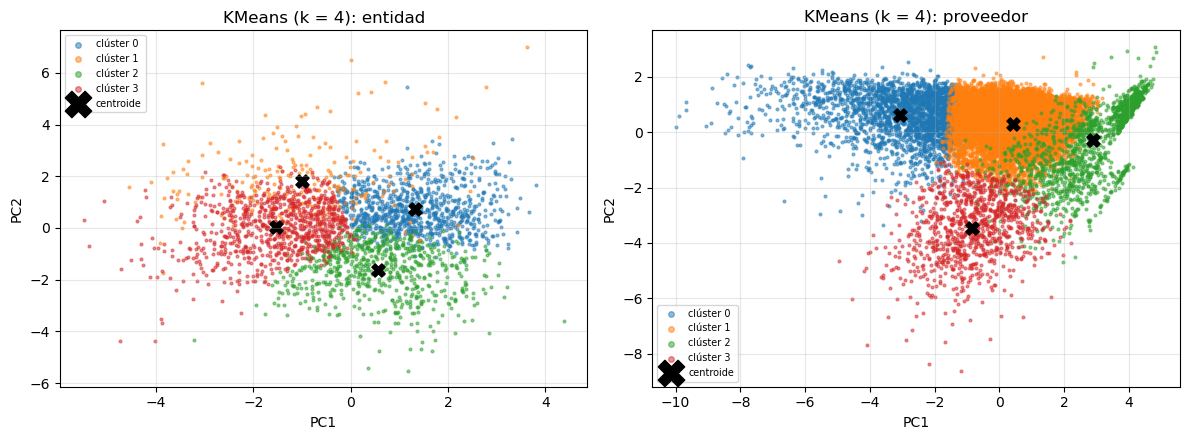

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for i, s in enumerate(config):
    loc = pd.read_parquet(datos_dir / f"prep_{s}").merge(pd.read_parquet(datos_dir / f"kmeans_{s}"), on=config[s]["key"])
    P, centros = np.vstack(loc.pcs.to_numpy()), np.array(modelos[(s, K[s])].clusterCenters())
    for c in range(K[s]):
        m = loc.cluster.to_numpy() == c
        ax[i].scatter(P[m, 0], P[m, 1], s=4, alpha=.5, label=f"clúster {c}")
    ax[i].scatter(centros[:, 0], centros[:, 1], c="black", marker="X", s=90, label="centroide")
    ax[i].set_title(f"KMeans (k = {K[s]}): {s}"); ax[i].set_xlabel("PC1"); ax[i].set_ylabel("PC2"); ax[i].legend(fontsize=7, markerscale=2)
mostrar_fig("kmeans_pca")

- **Mapa de perfiles:** qué tanto se diferencia cada clúster del promedio en cada feature, 

    - Medido en desviaciones estándar (σ)

    - Rojo = más que el promedio; azul = menos; blanco = como el promedio

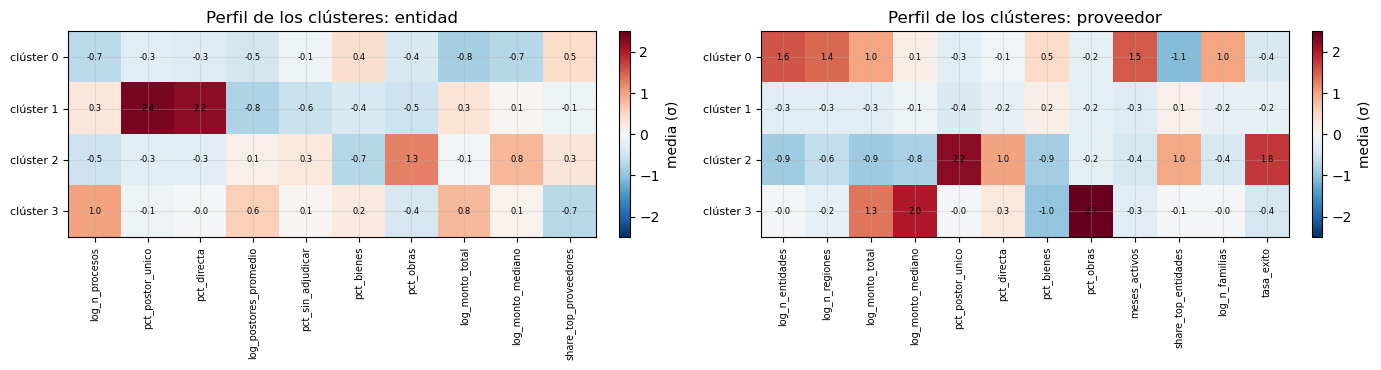

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for i, s in enumerate(config):
    feats = config[s]["feats"]
    loc = pd.read_parquet(datos_dir / f"prep_{s}").merge(pd.read_parquet(datos_dir / f"kmeans_{s}"), on=config[s]["key"])
    z = perfil_z(loc, feats, "cluster")[feats].astype(float)
    im = ax[i].imshow(z, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
    for (r, c), v in np.ndenumerate(z.to_numpy()):
        ax[i].text(c, r, f"{v:.1f}", ha="center", va="center", fontsize=6)
    ax[i].set_xticks(range(len(feats))); ax[i].set_xticklabels(feats, rotation=90, fontsize=7)
    ax[i].set_yticks(range(len(z))); ax[i].set_yticklabels([f"clúster {c}" for c in z.index], fontsize=8)
    ax[i].set_title(f"Perfil de los clústeres: {s}")
    fig.colorbar(im, ax=ax[i], fraction=0.046, pad=0.04, label="media (σ)")
mostrar_fig("perfiles_kmeans")

- **% de actores vs. % del monto:**

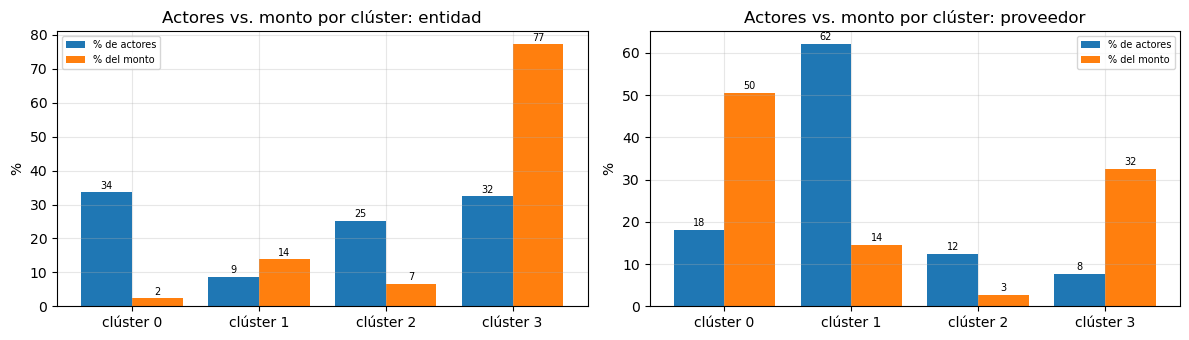

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i, s in enumerate(config):
    p, x = perfiles[s], np.arange(len(perfiles[s]))
    ax[i].bar(x - .2, p.pct_actores, .4, label="% de actores"); ax[i].bar(x + .2, p.pct_monto, .4, label="% del monto")
    for j, (a, b) in enumerate(zip(p.pct_actores, p.pct_monto)):
        ax[i].text(j - .2, a + 1, f"{a:.0f}", ha="center", fontsize=7); ax[i].text(j + .2, b + 1, f"{b:.0f}", ha="center", fontsize=7)
    ax[i].set_xticks(x); ax[i].set_xticklabels([f"clúster {c}" for c in p.index])
    ax[i].set_title(f"Actores vs. monto por clúster: {s}"); ax[i].set_ylabel("%"); ax[i].legend(fontsize=7)
mostrar_fig("actores_vs_monto")

In [ ]:
lejanos = pd.concat(lejanos)
lejanos

,clave,nombre,cluster,dist_centro,n_procesos,monto,sujeto
2194,ENT:205250,AUTORIDAD NACIONAL DE CONTROL DEL MINISTERIO PÚBLICO,1,9.702132,5,8.465000e+05,entidad
1364,ENT:205170,FORTALECIMIENTO DEL SISTEMA NACIONAL DE VIGILANCIA EN SALUD PÚBLICA,1,8.096230,8,1.410137e+05,entidad
2657,ENT:202125,UNIDAD EJECUTORA 411 SALUD JULCAN,1,8.054921,6,1.347605e+06,entidad
2094,ENT:86,MUNICIPALIDAD DISTRITAL DE SOLOCO,1,7.590630,5,3.371322e+06,entidad
1515,ENT:204950,PROGRAMA NACIONAL DE INVESTIGACIÓN CIENTÍFICA Y ESTUDIOS AVANZADOS,0,6.968740,62,4.207181e+06,entidad
2640,ENT:200366,PROYECTO DE MODERNIZACION DE LA GESTION DE LOS RECURSOS HIDRICOS,1,6.890773,12,2.867238e+07,entidad
2271,ENT:74,MUNICIPALIDAD DISTRITAL DE HUANCAS - AMAZONAS,1,6.794252,5,1.103210e+07,entidad
2171,ENT:203748,UNIDAD EJECUTORA 005: VENTANILLA UNICA DE COMERCIO EXTERIOR - SEGUNDA ETAPA,1,6.709942,5,1.491763e+05,entidad
819,ENT:205591,CONGRESO DE LA REPÚBLICA - IMPLEMENT. DEL MODELO DE LA INFRAESTRUC. Y FUNCIO...,1,6.606855,5,2.377147e+06,entidad
2690,ENT:1856,MUNICIPALIDAD DISTRITAL DE HUANUARA,2,6.587264,6,1.620000e+05,entidad


- **Entidades:** los más lejanos son del clúster "sin competencia"

- 100% de contratación directa en pocos procesos

- **Proveedores:** grandes nacionales (Diagnóstica Peruana, Ferreyros, IPESA, Unimaq)

- Muchos son actores singulares por mandato o tamaño, no irregulares

#### a. Verificación

- Una etiqueta por actor, en todos los actores del clustering

In [18]:
for s in config:
    km = pd.read_parquet(datos_dir / f"kmeans_{s}")
    assert km[config[s]["key"]].is_unique and len(km) == prep[s].count() and km.cluster.between(0, K[s] - 1).all(), s
    print(f"{s}: {len(km):,} etiquetas en {K[s]} clústeres | OK")

entidad: 2,696 etiquetas en 4 clústeres | OK
proveedor: 13,317 etiquetas en 4 clústeres | OK


---
### **7. Escritura de resultados**

In [19]:
escritos = guardar_tablas({
    "curvas_k": curvas, "inicializacion": inicios, "estabilidad": estabilidad, "espacio": espacio, "referencia_sklearn": referencia,
    "perfiles_kmeans": pd.concat({s: p.reset_index() for s, p in perfiles.items()}).reset_index(level=0).rename(columns={"level_0": "sujeto"}),
    "lejanos_centroide": lejanos})

Escrito en 02_Clustering/temp/b_kmeans/: curvas_k, inicializacion, estabilidad, espacio, referencia_sklearn, perfiles_kmeans, lejanos_centroide


#### a. Verificación

In [20]:
verificar_salidas(escritos)

OK: 7 tablas (parquet + json) | 4 figuras: actores_vs_monto, eleccion_k, kmeans_pca, perfiles_kmeans


---
### **8. Cerrar sesión**

In [21]:
spark.stop()